In [1]:
# Arpit Huss (E23CSEU0554)


Using Colab cache for faster access to the 'heart-failure-clinical-data' dataset.
First 5 Rows:
    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7           116    0   

   smoki

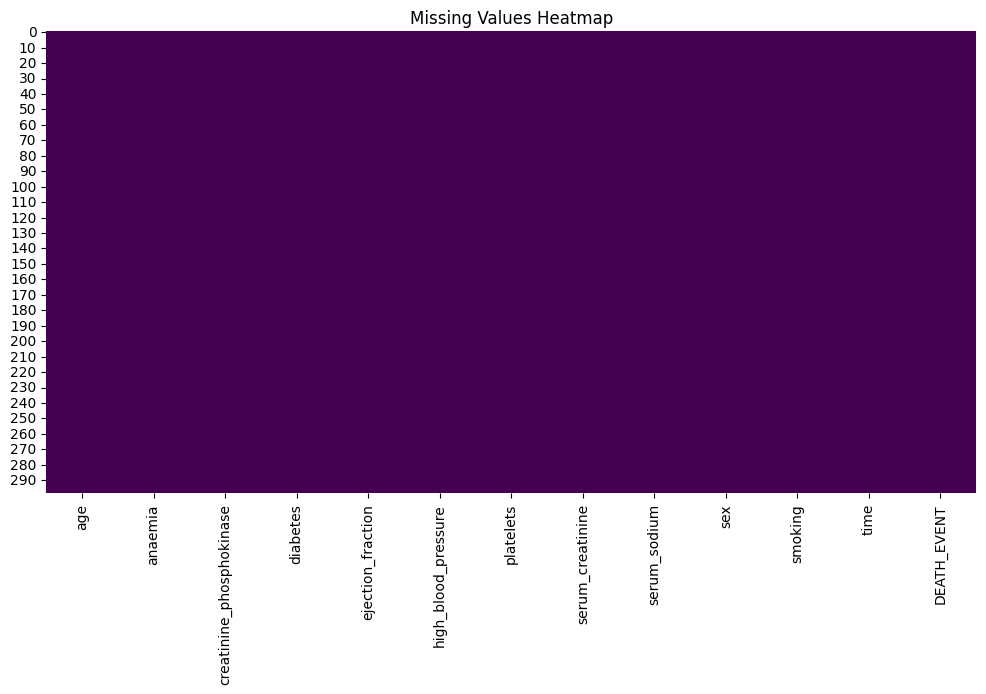

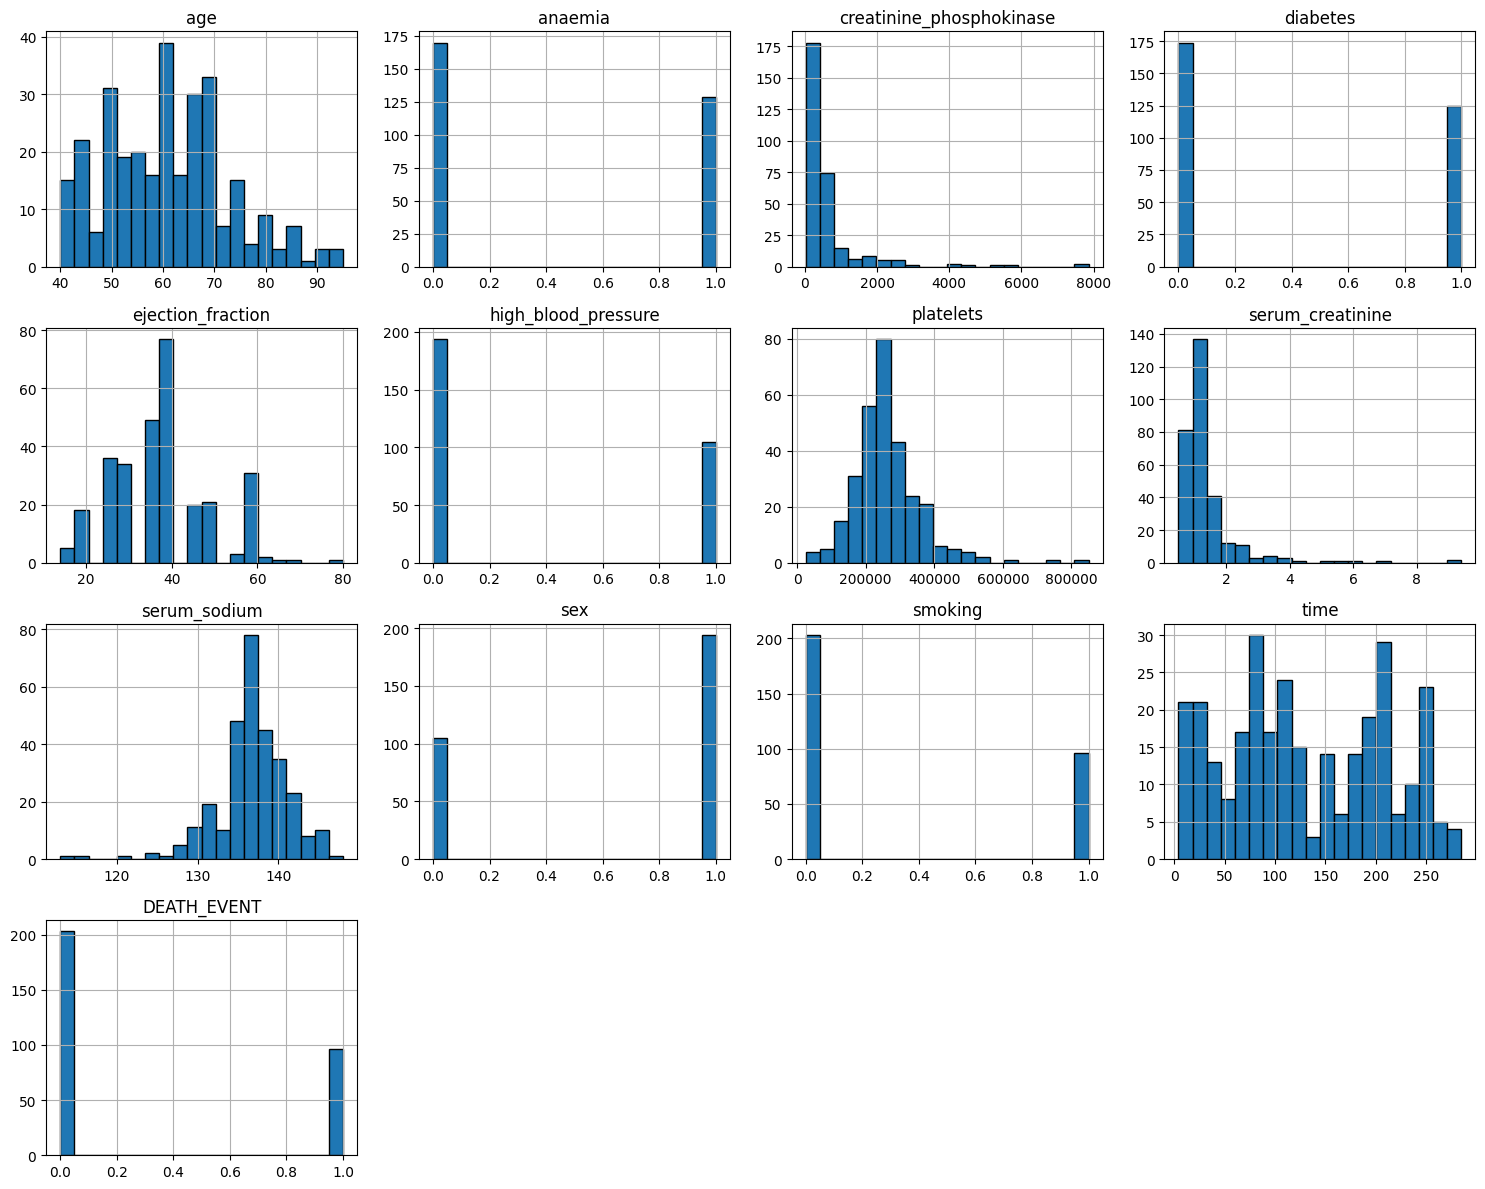

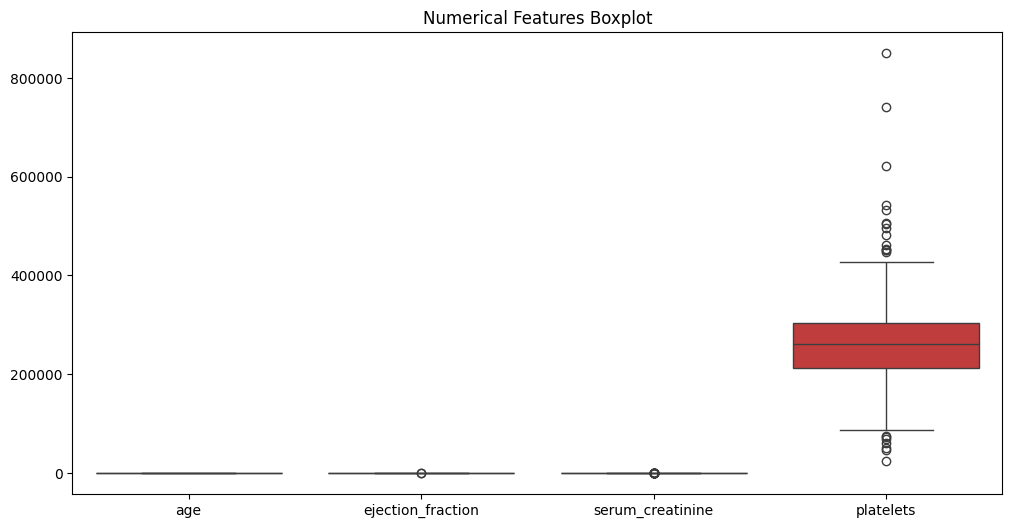


Dataset Shape After Outlier Removal: (224, 13)

Model Evaluation
Accuracy: 0.8444444444444444
Precision: 0.8571428571428571
Recall: 0.5
F1 Score: 0.631578947368421
AUROC: 0.9280303030303031

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.97      0.90        33
           1       0.86      0.50      0.63        12

    accuracy                           0.84        45
   macro avg       0.85      0.73      0.77        45
weighted avg       0.85      0.84      0.83        45



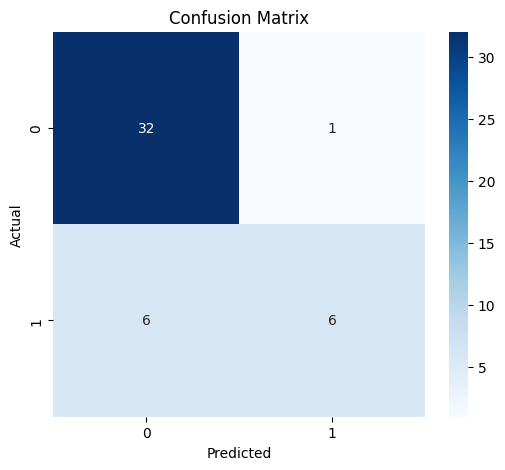

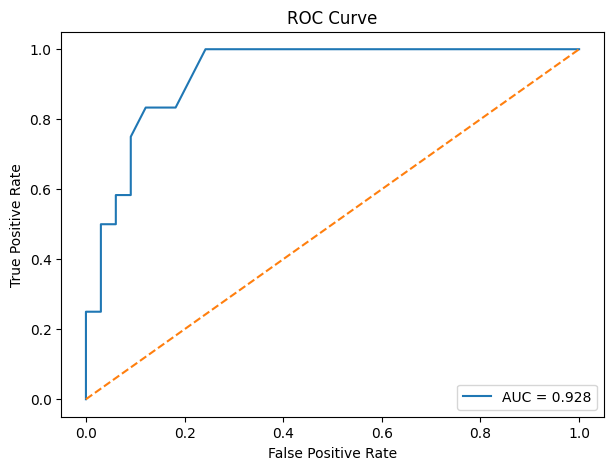

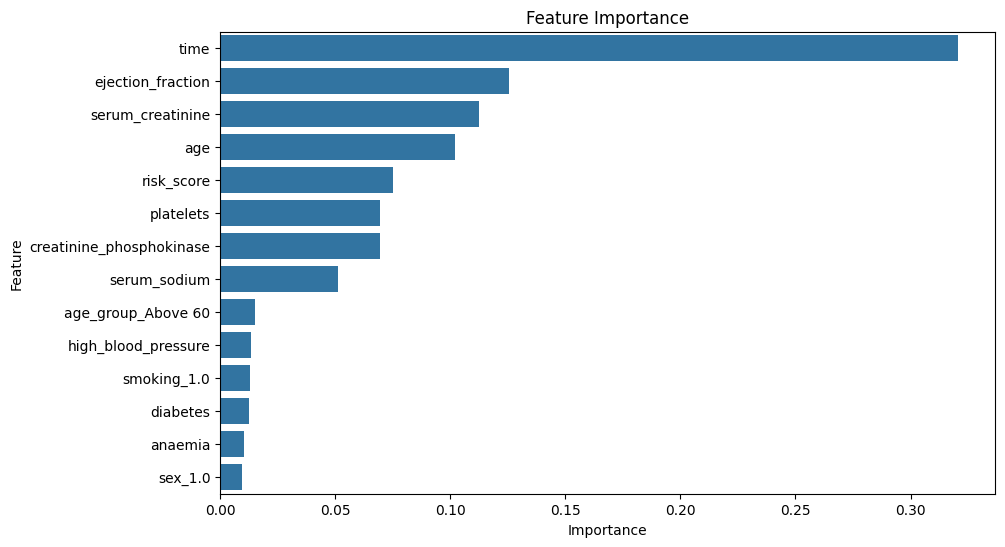


Feature Importance:
                     Feature  Importance
9                       time    0.320718
4          ejection_fraction    0.125687
7           serum_creatinine    0.112334
0                        age    0.102185
10                risk_score    0.075271
6                  platelets    0.069609
2   creatinine_phosphokinase    0.069500
8               serum_sodium    0.051072
13        age_group_Above 60    0.015301
5        high_blood_pressure    0.013222
12               smoking_1.0    0.012945
3                   diabetes    0.012453
1                    anaemia    0.010191
11                   sex_1.0    0.009509


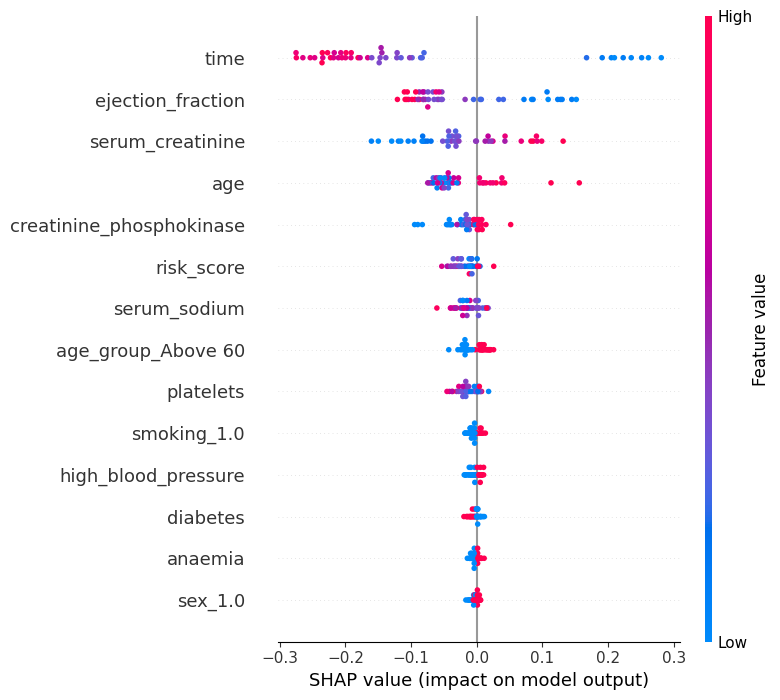


Individual Prediction:
Predicted Class: 0
Survival Probability: 0.91
Death Event Probability: 0.09


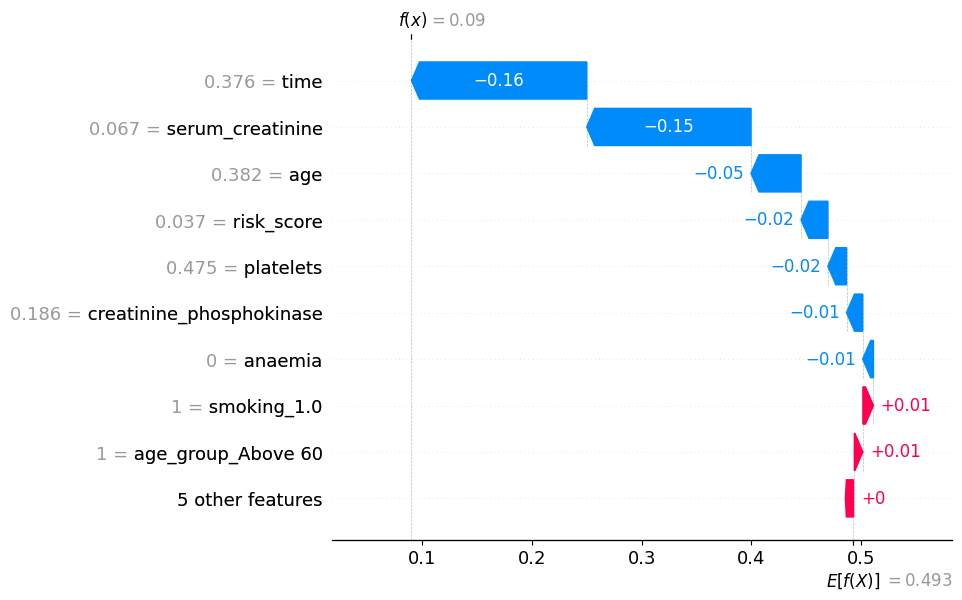


Assignment Completed Successfully


In [2]:

!pip install -q kagglehub shap

import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve

path = kagglehub.dataset_download("andrewmvd/heart-failure-clinical-data")
files = glob.glob(os.path.join(path, "*.csv"))
df = pd.read_csv(files[0])

print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.show()

df.hist(figsize=(15, 12), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[["age", "ejection_fraction", "serum_creatinine", "platelets"]])
plt.title("Numerical Features Boxplot")
plt.show()

df.replace([np.inf, -np.inf], np.nan, inplace=True)

invalid_features = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium",
    "time"
]

for col in invalid_features:
    df.loc[df[col] < 0, col] = np.nan

categorical_features = [
    "anaemia",
    "diabetes",
    "high_blood_pressure",
    "sex",
    "smoking"
]

for col in categorical_features:
    df.loc[~df[col].isin([0, 1]), col] = np.nan
    df[col] = df[col].fillna(df[col].mode()[0])

numerical_features = df.select_dtypes(include=np.number).columns.tolist()
numerical_features.remove("DEATH_EVENT")

for col in numerical_features:
    df[col] = df[col].fillna(df[col].median())

outlier_features = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium",
    "time"
]

for col in outlier_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower) & (df[col] <= upper)]

df.reset_index(drop=True, inplace=True)

print("\nDataset Shape After Outlier Removal:", df.shape)

df["age_group"] = np.select(
    [df["age"] < 40, df["age"] <= 60],
    ["Below 40", "40-60"],
    default="Above 60"
)

ef_range = df["ejection_fraction"].max() - df["ejection_fraction"].min()
sc_range = df["serum_creatinine"].max() - df["serum_creatinine"].min()

ef_norm = (df["ejection_fraction"] - df["ejection_fraction"].min()) / ef_range if ef_range else 0
sc_norm = (df["serum_creatinine"] - df["serum_creatinine"].min()) / sc_range if sc_range else 0

df["risk_score"] = ef_norm * sc_norm

df = pd.get_dummies(
    df,
    columns=["sex", "smoking", "age_group"],
    drop_first=True,
    dtype=int
)

X = df.drop("DEATH_EVENT", axis=1)
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = MinMaxScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("\nModel Evaluation")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("AUROC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Feature Importance")
plt.show()

print("\nFeature Importance:")
print(importance)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_scaled)

if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

shap.summary_plot(shap_values, X_test_scaled)

sample = X_test_scaled.iloc[[0]]

prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0]

print("\nIndividual Prediction:")
print("Predicted Class:", prediction)
print("Survival Probability:", probability[0])
print("Death Event Probability:", probability[1])

base_value = explainer.expected_value
if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[1]

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=base_value,
        data=sample.iloc[0].values,
        feature_names=sample.columns.tolist()
    )
)

print("\nAssignment Completed Successfully")
